# M4: Initial Insights

Question: which Metro Manila cities have the most connection-seeking posts per capita, and what kind of posts (friendship, romance, sexual) are they?

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# same color for each intent in every chart
intent_colors = {"platonic": "tab:blue", "romantic": "tab:red", "sexual": "black", "all": "lightgray"}

df = pd.read_csv("../data/processed/posts_clean.csv", low_memory=False)
df["date_manila"] = pd.to_datetime(df["date_manila"])
print(len(df), "posts")
df[["post_id", "subreddit", "category", "date_manila", "city"]].head(3)


## Notes on the data

- The archive is thin before Aug 2025 (about 20 posts a day, then about 550 a day after). I only use Aug 2025 onward.
- Only about 36% of posts mention a city, so the city charts only cover those posts.
- The gazetteer also matches Cavite, Laguna, Rizal, Bulacan and Antipolo. I leave those out of the city charts since they are not in Metro Manila.
- "Metro Manila" is a region label, not a city, so a post that only says "Metro Manila" is left out of the city charts. If a post names two cities, it goes to the first one mentioned.
- The population table and the weather data are new in M4. I forgot in M3 that "per capita" needs a population number.


In [2]:
df_window = df[df["date_manila"] >= "2025-08-01"].copy()
print(len(df_window), "posts from", df_window["date_manila"].min().date(), "to", df_window["date_manila"].max().date())

197082 posts from 2025-08-01 to 2026-08-03


## Summary statistics

In [3]:
df_window[["score", "num_comments", "seeker_age"]].describe().round(1)

,score,num_comments,seeker_age
count,197082.0,197082.0,195723.0
mean,2.1,0.7,26.8
std,4.0,1.0,4.6
min,0.0,0.0,1.0
25%,1.0,0.0,24.0
50%,1.0,1.0,26.0
75%,2.0,1.0,29.0
max,250.0,52.0,99.0


In [4]:
df_window.groupby("category")["seeker_age"].median()

category
all         27.0
platonic    26.0
romantic    27.0
sexual      26.0
Name: seeker_age, dtype: float64

Most posts get very little attention. The median score is 1 and the median number of comments is 1, but a few posts go much higher (the top score is 250), which is why the mean score is higher than the median.

The median age is 26 and it is about the same in every category. A few ages like 1 and 99 are title parsing mistakes, so I ignore them.

## Chart plan

| # | Question | Chart | Columns |
|---|----------|-------|---------|
| 1 | When do people post? | stacked bar | hour_manila, category |
| 2 | Which cities post the most per capita? | horizontal bar | city, posts per 100k |
| 3 | What intent does each city lean toward? | grouped bar | city, category |
| 4 | Does rain change how much people post? | bar | precip_sum, posts per day |
| 5 | Which gender posts more and gets more upvotes and comments? | grouped bar | seeker_gender, category, score, num_comments |

### Adding population

New in M4. `metro_manila_population.csv` has 2024 census numbers (PSA PSGC cities table) for the 16 NCR cities, with PSGC codes. Pateros is left out (see Limits).

In [5]:
# new in M4, I forgot I needed this for per capita
pop = pd.read_csv("../data/reference/metro_manila_population.csv")
pop_lookup = dict(zip(pop["city"], pop["population"]))

city_posts = df_window[df_window["city"].isin(pop_lookup)].groupby("city").size().rename("posts").reset_index()
city_posts["population"] = city_posts["city"].map(pop_lookup)
city_posts["posts_per_100k"] = (city_posts["posts"] / city_posts["population"] * 100_000).round(1)
city_posts.sort_values("posts_per_100k", ascending=False).reset_index(drop=True)

,city,posts,population,posts_per_100k
0,Makati,8965,309770,2894.1
1,Manila,14199,1902590,746.3
2,Quezon City,18287,3084270,592.9
3,Mandaluyong,2244,465902,481.6
4,Taguig,5918,1308085,452.4
5,Pasay,1942,453186,428.5
6,Pasig,3238,853050,379.6
7,Marikina,1645,471323,349.0
8,San Juan,416,134312,309.7
9,Muntinlupa,1414,552225,256.1


## Chart 1: when people post

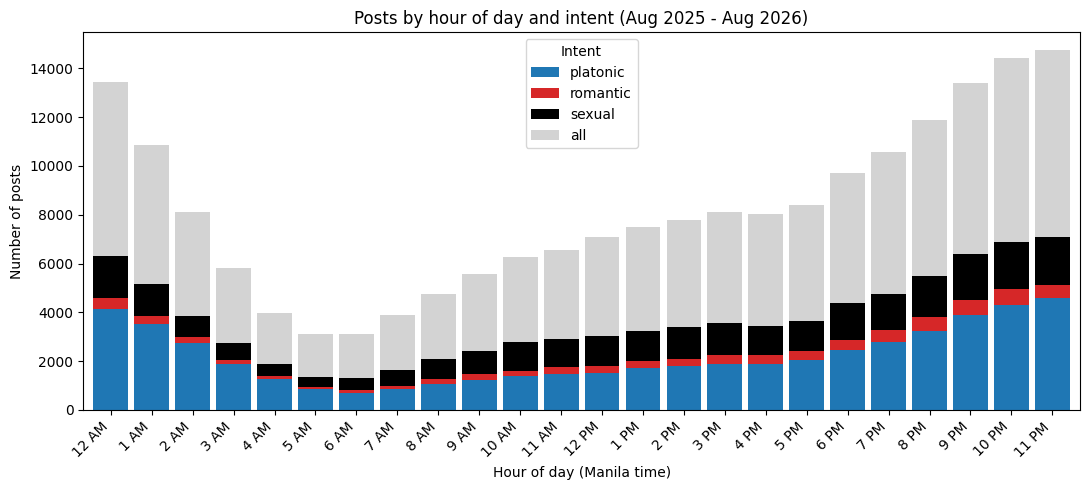

In [6]:
hourly = df_window.pivot_table(index="hour_manila", columns="category", values="post_id", aggfunc="count").fillna(0)
hourly = hourly[["platonic", "romantic", "sexual", "all"]]

labels = []
for h in hourly.index:
    suffix = "AM" if h < 12 else "PM"
    labels.append(str(h % 12 or 12) + " " + suffix)
hourly.index = labels

ax = hourly.plot(kind="bar", stacked=True, figsize=(11, 5), width=0.85,
                 color=[intent_colors[c] for c in hourly.columns])
ax.set_title("Posts by hour of day and intent (Aug 2025 - Aug 2026)")
ax.set_xlabel("Hour of day (Manila time)")
ax.set_ylabel("Number of posts")
ax.legend(title="Intent")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("../output/figures/fig1_posts_by_hour_and_intent.png", dpi=120)
plt.show()

Posting is lowest around 5 to 6 AM and highest around 11 PM. About 27% of all posts are made between 10 PM and 2 AM. All the intent types follow the same shape, so friendship posts are not earlier than the others.

Possible use: support lines or community groups that want to reach people should be active late at night.

## Chart 2: cities per capita

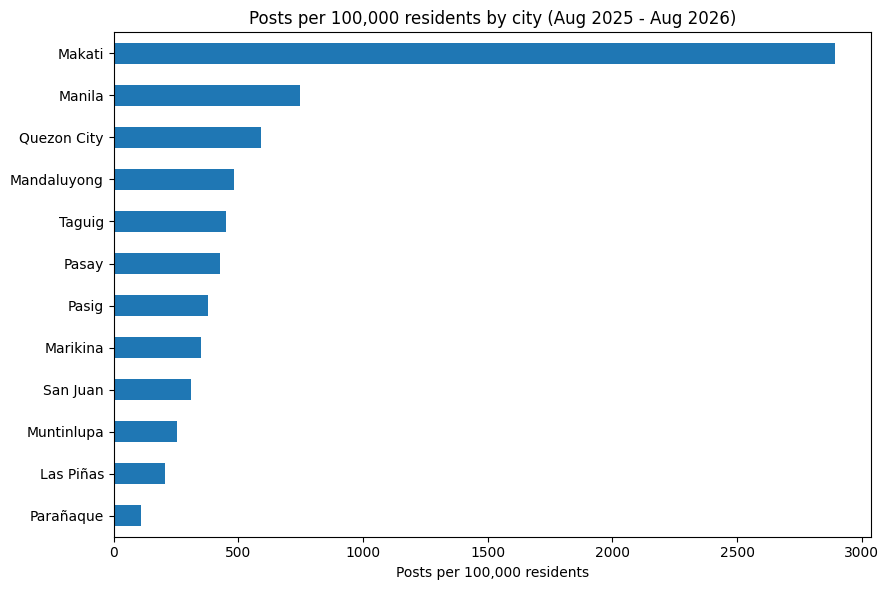

In [7]:
top = city_posts.sort_values("posts_per_100k", ascending=False).head(12).sort_values("posts_per_100k")

ax = top.plot(x="city", y="posts_per_100k", kind="barh", figsize=(9, 6), legend=False)
ax.set_title("Posts per 100,000 residents by city (Aug 2025 - Aug 2026)")
ax.set_xlabel("Posts per 100,000 residents")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../output/figures/fig2_cities_per_capita.png", dpi=120)
plt.show()

In [8]:
city_posts["rank_volume"] = city_posts["posts"].rank(ascending=False).astype(int)
city_posts["rank_per_capita"] = city_posts["posts_per_100k"].rank(ascending=False).astype(int)
city_posts.sort_values("rank_per_capita")[["city", "posts", "posts_per_100k", "rank_volume", "rank_per_capita"]].head(10)

,city,posts,posts_per_100k,rank_volume,rank_per_capita
2,Makati,8965,2894.1,3,1
5,Manila,14199,746.3,2,2
12,Quezon City,18287,592.9,1,3
4,Mandaluyong,2244,481.6,6,4
14,Taguig,5918,452.4,4,5
10,Pasay,1942,428.5,7,6
11,Pasig,3238,379.6,5,7
6,Marikina,1645,349.0,8,8
13,San Juan,416,309.7,14,9
7,Muntinlupa,1414,256.1,9,10


Makati is first by a wide margin with about 2,890 posts per 100,000 residents. Manila is second at about 746 and Quezon City is third at about 593. By raw volume Quezon City is first, Manila second and Makati third, so dividing by population puts Makati on top. San Juan also moves up, from 14th by volume to 9th per capita.

For community builders, the gap matters more than the raw count: Makati's rate is about 3.9x Manila's and 4.9x Quezon City's, which makes it the best first test for a late-night social space even though Manila and Quezon City reach more people.

Navotas has very few posts (8), so its number does not mean much.


## Chart 3: intent by city

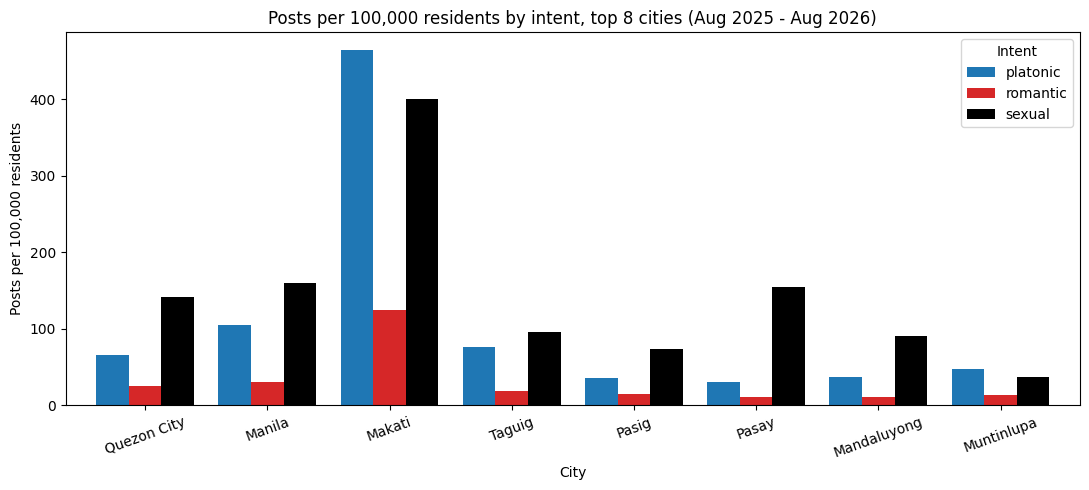

,platonic,romantic,sexual
city,,,
Quezon City,65.4,25.0,142.0
Manila,104.9,31.1,160.2
Makati,464.2,124.6,400.0
Taguig,76.4,18.7,96.0
Pasig,35.4,14.7,73.4
Pasay,30.7,11.0,154.9
Mandaluyong,36.7,11.2,90.6
Muntinlupa,47.4,13.8,37.5


In [9]:
by_city = df_window[df_window["city"].isin(pop_lookup)].pivot_table(
    index="city", columns="category", values="post_id", aggfunc="count"
).fillna(0)
by_city["total"] = by_city[["platonic", "romantic", "sexual"]].sum(axis=1)
by_city = by_city.nlargest(8, "total")

rates = pd.DataFrame(index=by_city.index)
for col in ["platonic", "romantic", "sexual"]:
    rates[col] = by_city[col] / by_city.index.map(pop_lookup) * 100_000

ax = rates.plot(kind="bar", figsize=(11, 5), width=0.8,
                color=[intent_colors[c] for c in rates.columns])
ax.set_title("Posts per 100,000 residents by intent, top 8 cities (Aug 2025 - Aug 2026)")
ax.set_xlabel("City")
ax.set_ylabel("Posts per 100,000 residents")
ax.legend(title="Intent")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("../output/figures/fig3_intent_mix_by_city.png", dpi=120)
plt.show()
rates.round(1)

Makati is highest for every intent. Platonic is about 464 per 100,000 and sexual is about 400. Romantic is the smallest in every city.

Pasay stands out because its platonic rate is low (about 31) but its sexual rate is about 155, which is higher than Quezon City's. The counts are small for some cities, so I would treat this as a pointer and not a firm result.

Possible use: community spaces could look at Makati, Manila and Taguig. Health programs could look at Pasay, where sexual posts are far more common than friendship posts.


## Chart 4: rain and posting

In [10]:
weather = pd.read_csv("../data/reference/manila_daily_weather.csv")
weather["date"] = pd.to_datetime(weather["date"])

daily = df_window.groupby("date_manila").size().rename("posts").reset_index()
daily = daily.rename(columns={"date_manila": "date"}).merge(weather, on="date", how="left")
print("days with no weather row:", daily["precip_sum"].isna().sum())

daily["rainy"] = daily["precip_sum"] > 0
daily["weekend"] = daily["date"].dt.dayofweek >= 5
print("rainy days:", daily["rainy"].sum(), " dry days:", (~daily["rainy"]).sum())

days with no weather row: 0
rainy days: 299  dry days: 69


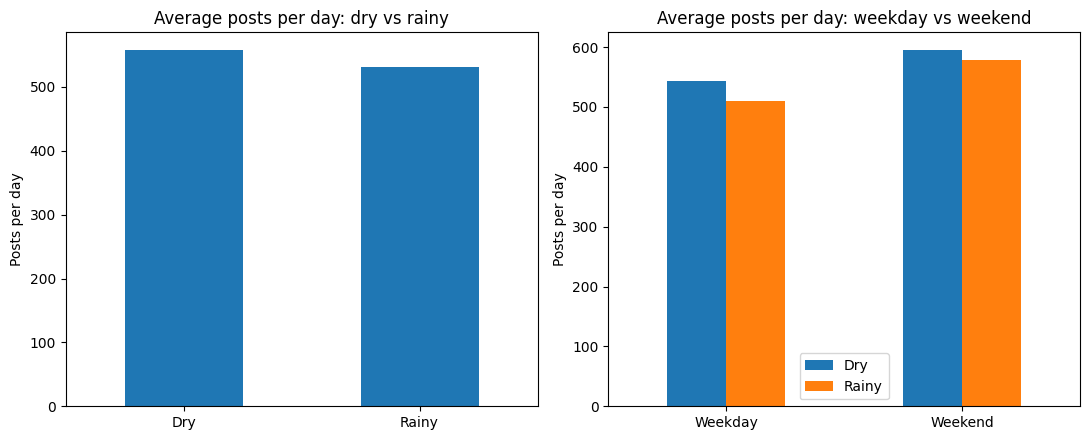

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

daily.groupby("rainy")["posts"].mean().rename({False: "Dry", True: "Rainy"}).plot(kind="bar", ax=axes[0])
axes[0].set_title("Average posts per day: dry vs rainy")
axes[0].set_xlabel("")
axes[0].set_ylabel("Posts per day")

by_group = daily.groupby(["weekend", "rainy"])["posts"].mean().unstack()
by_group.index = ["Weekday", "Weekend"]
by_group.columns = ["Dry", "Rainy"]
by_group.plot(kind="bar", ax=axes[1])
axes[1].set_title("Average posts per day: weekday vs weekend")
axes[1].set_xlabel("")
axes[1].set_ylabel("Posts per day")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../output/figures/fig4_rain_vs_posting.png", dpi=120)
plt.show()

Rainy days have slightly fewer posts than dry days (about 530 vs 558). Weekends have more posts than weekdays (about 582 vs 517), and that difference is bigger than the rain difference. So the "rainy weekend" idea from the problem statement does not show up in this data.

## Inference check: does rain change posting?

In [12]:
rainy = daily.loc[daily["rainy"], "posts"]
dry = daily.loc[~daily["rainy"], "posts"]
print("rainy mean", round(rainy.mean(), 1), " dry mean", round(dry.mean(), 1))
print("t-test p-value:", round(stats.ttest_ind(rainy, dry, equal_var=False).pvalue, 4))

rho, p = stats.spearmanr(daily["precip_sum"], daily["posts"])
print("spearman rho:", round(rho, 3), " p-value:", f"{p:.1e}")

wk = daily[daily["weekend"]]
print("weekends only, rainy vs dry p-value:",
      round(stats.ttest_ind(wk.loc[wk["rainy"], "posts"], wk.loc[~wk["rainy"], "posts"], equal_var=False).pvalue, 3))
print("weekend vs weekday mean:", round(daily.loc[daily["weekend"], "posts"].mean(), 1),
      round(daily.loc[~daily["weekend"], "posts"].mean(), 1))

rainy mean 530.5  dry mean 557.6
t-test p-value: 0.0023
spearman rho: -0.273  p-value: 9.9e-08
weekends only, rainy vs dry p-value: 0.388
weekend vs weekday mean: 581.9 516.8


In [13]:
# temperature, checked two ways: raw, and within the same month
rho_raw, p_raw = stats.spearmanr(daily["temp_mean"], daily["posts"])
print(f"raw: rho={rho_raw:.3f}  p={p_raw:.1e}")

daily["month"] = daily["date"].dt.month
daily["posts_centred"] = daily["posts"] - daily.groupby("month")["posts"].transform("mean")
daily["temp_centred"] = daily["temp_mean"] - daily.groupby("month")["temp_mean"].transform("mean")
rho_m, p_m = stats.spearmanr(daily["temp_centred"], daily["posts_centred"])
print(f"within the same month: rho={rho_m:.3f}  p={p_m:.3f}")

raw: rho=0.290  p=1.5e-08
within the same month: rho=-0.088  p=0.093


Temperature follows the same pattern as rain. Hotter days look like they have more posts (rho +0.29), but that is mostly the calendar. The hot months from March to May are also the busiest, and they are the dry ones. Comparing days within the same month, the link is close to zero and not significant (rho -0.09, p = 0.09). So I don't see a temperature effect I'd report.

**Compared:** rainy days vs dry days, by posts per day.

**Result:** rainy days average about 530 posts and dry days about 558. The gap is small, and unlikely to be chance (p about 0.002). On weekends alone the gap disappears (p about 0.39).

**Takeaway:** rainy days have slightly fewer posts, and weekends have more.

**Caveats:** this does not show rain causes fewer posts. The rainiest months (Aug and Sep) are also the quietest, so rain and time of year can't be separated. There are only 69 dry days, one weather point covers the whole metro, and these are Reddit posts, not everyone in the city.

## Chart 5: which gender posts more, and which gets more upvotes and comments?

Gender here is the first part of the title tag (M4F means a man looking for a woman). I only use M and F, which is about 98% of the posts. Tags like TF and couples are left out.

In [14]:
mf = df_window[df_window["seeker_gender"].isin(["M", "F"])].copy()
print(len(mf), "of", len(df_window), "posts are M or F")
print(mf["seeker_gender"].value_counts(normalize=True).round(3).to_string())

# score above 1 means somebody besides the poster upvoted it
mf["upvoted"] = mf["score"] > 1
mf["commented"] = mf["num_comments"] > 0

counts = mf.pivot_table(index="category", columns="seeker_gender", values="post_id", aggfunc="count")
counts["percent_women"] = (counts["F"] / (counts["F"] + counts["M"]) * 100).round(1)
counts

192288 of 197082 posts are M or F
seeker_gender
M    0.622
F    0.378


seeker_gender,F,M,percent_women
category,,,
all,32460,72319,31.0
platonic,30602,22359,57.8
romantic,4019,3527,53.3
sexual,5588,21414,20.7


In [15]:
engagement = mf.groupby(["category", "seeker_gender"])[["upvoted", "commented"]].mean().round(3)
print(engagement.unstack().to_string())
print()
print("everyone together:")
print(mf.groupby("seeker_gender")[["upvoted", "commented"]].mean().round(3).to_string())

              upvoted        commented       
seeker_gender       F      M         F      M
category                                     
all             0.589  0.092     0.999  0.999
platonic        0.589  0.311     0.054  0.068
romantic        0.533  0.474     0.741  0.529
sexual          0.659  0.087     0.613  0.054

everyone together:
               upvoted  commented
seeker_gender                    
F                0.591      0.557
M                0.143      0.642


In [16]:
# comments only mean something in some subreddits
by_cat = df_window.groupby("category")["num_comments"]
pd.DataFrame({
    "share_with_comment": by_cat.apply(lambda s: (s > 0).mean()),
    "share_with_exactly_1": by_cat.apply(lambda s: (s == 1).mean()),
}).round(3)

,share_with_comment,share_with_exactly_1
category,,
all,0.999,0.994
platonic,0.061,0.057
romantic,0.643,0.239
sexual,0.175,0.068


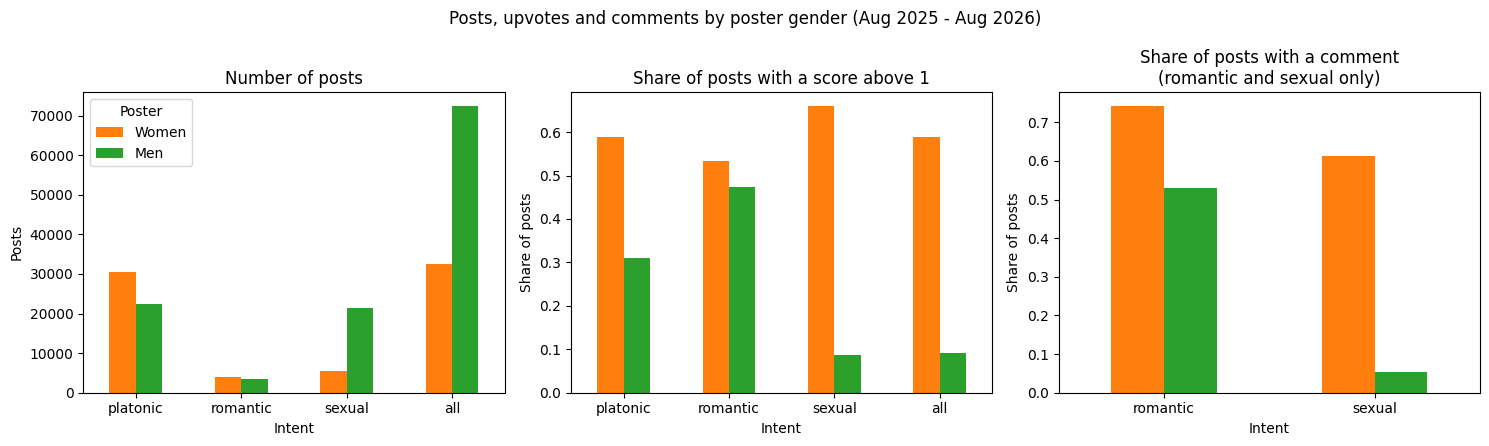

In [17]:
order = ["platonic", "romantic", "sexual", "all"]
cols = ["F", "M"]
names = {"F": "Women", "M": "Men"}
gender_colors = ["tab:orange", "tab:green"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

counts.loc[order, cols].rename(columns=names).plot(kind="bar", ax=axes[0], color=gender_colors)
axes[0].set_title("Number of posts")
axes[0].set_ylabel("Posts")

engagement["upvoted"].unstack().loc[order, cols].rename(columns=names).plot(kind="bar", ax=axes[1], color=gender_colors, legend=False)
axes[1].set_title("Share of posts with a score above 1")
axes[1].set_ylabel("Share of posts")

engagement["commented"].unstack().loc[["romantic", "sexual"], cols].rename(columns=names).plot(kind="bar", ax=axes[2], color=gender_colors, legend=False)
axes[2].set_title("Share of posts with a comment\n(romantic and sexual only)")
axes[2].set_ylabel("Share of posts")

for ax in axes:
    ax.set_xlabel("Intent")
    ax.tick_params(axis="x", rotation=0)
axes[0].legend(title="Poster")
plt.suptitle("Posts, upvotes and comments by poster gender (Aug 2025 - Aug 2026)")
plt.tight_layout()
plt.savefig("../output/figures/fig5_gender.png", dpi=120)
plt.show()

Men post more overall, about 62% of posts against 38% for women. It depends on the subreddit though. Women are the majority in platonic (58%) and romantic (53%), while men are about 79% of the sexual posts and 69% of the general (phr4r_2) posts.

Women get more upvotes. About 59% of women's posts have a score above 1 compared to 14% of men's posts, and women are ahead in every category. The gap is smallest in romantic (53% vs 47%).

Women also get more comments, but only where comments can be compared: 74% vs 53% in romantic and 61% vs 5% in sexual. I left out the other two. Almost every phr4r_2 post has exactly one comment (it looks like an automatic comment) and PhR4Friends posts hardly get comments. If I mix everything together, men look like they get more comments (64% vs 56%), but that only happens because most men post in phr4r_2.

This does not mean women's posts are better. I did not test why the gap exists. Most posters are men, so most of the people reading and replying may be too, and the posts are not the same kind. I would treat this as a description only.

Possible use: for outreach on casual sex, the people posting are mostly men. For friendship-seeking, the audience is more women.

## Summary

- **Per capita:** Makati has the most posts per capita, then Manila and Quezon City. Posts are mostly friendship and sexual intent, with romantic the smallest.
- **Intent:** Makati leads in all three. Pasay is unusual because it leans toward sexual posts.
- **Timing:** posts peak late at night and on weekends. Rain does not increase posting.
- **Gender:** men post more overall (62%), but women are the majority in platonic and romantic posts. Women get more upvotes in every category and more comments where comments can be compared.

## Limits

- Only about 36% of posts name a city, so the city results only describe those posts. City matching takes the first city mentioned, so a post that names two cities is counted once.
- Reddit posters are not a sample of everyone in the city.
- Gender comes from the tag in the title (like M4F), so it is what the person wrote. About 2% of posts use other tags and are left out of the gender chart.
- Population is the 2024 POPCEN figure from the PSA PSGC cities table. Pateros is left out: it is a municipality, not in that table, and it has only 3 posts.
